In [42]:
import torch
import torch.nn as nn
import kagglehub
from pathlib import Path

# download mnist dataset from kaggle
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

# inspecting the files
for file in Path(path).rglob("*"):
    if file.is_file():
        print(file)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mnist-dataset' dataset.
/kaggle/input/mnist-dataset/train-images.idx3-ubyte
/kaggle/input/mnist-dataset/t10k-labels.idx1-ubyte
/kaggle/input/mnist-dataset/t10k-images.idx3-ubyte
/kaggle/input/mnist-dataset/train-labels.idx1-ubyte
/kaggle/input/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte
/kaggle/input/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte
/kaggle/input/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte
/kaggle/input/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte
Path to dataset files: /kaggle/input/mnist-dataset


In [43]:
import struct, numpy as np
from torch.utils.data import TensorDataset, DataLoader

def read_images(p):
    with open(p, "rb") as f:
        _, n, r, c = struct.unpack(">IIII", f.read(16))
        return torch.from_numpy(np.frombuffer(f.read(), dtype=np.uint8).copy()).view(n, 1, r, c).float() / 255

def read_labels(p):
    with open(p, "rb") as f:
        f.read(8)
        return torch.from_numpy(np.frombuffer(f.read(), dtype=np.uint8).copy()).long()

root = Path(path)

def find_file(prefix):
    # match real files only, skip the same-named folders
    return next(p for p in root.rglob(prefix + "*") if p.is_file())

Xtr = (read_images(find_file("train-images")) - 0.1307) / 0.3081
ytr = read_labels(find_file("train-labels"))
Xte = (read_images(find_file("t10k-images")) - 0.1307) / 0.3081
yte = read_labels(find_file("t10k-labels"))

train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)
test_loader  = DataLoader(TensorDataset(Xte, yte), batch_size=256)

In [44]:
# fixed seed so the results can be reproduced
torch.manual_seed(0)

# lets define a simple CNN architecture
CNNmodel = nn.Sequential(    

    # first convolutional layer (3x3 kernel, 16 output channels, stride 1, padding 1)
    nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1),
    nn.BatchNorm2d(16), # batch normalization layer
    nn.ReLU(), # activation function
    nn.MaxPool2d(kernel_size=2, stride=2), # max pooling layer

    # second convolutional layer (3x3 kernel, 32 output channels, stride 1, padding 1)
    nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    # third convolutional layer (3x3 kernel, 64 output channels, stride 1, padding 1)
    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    # fully connected layer (flatten the output and connect to 128 neurons)
    nn.Flatten(),

    # fully connected layer (128 neurons)
    nn.Linear(in_features=64 * 3 * 3, out_features=128),
    nn.ReLU(),

    # regularization layer to prevent overfitting
    nn.Dropout(0.5),

    # output layer (10 classes for classification)
    nn.Linear(in_features=128, out_features=10)
)

# define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(CNNmodel.parameters(), lr=0.001, weight_decay=1e-4)


In [45]:
# a simple architecture and device check
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CNNmodel = CNNmodel.to(device)

print("Selected device:", device)

dummy_input = torch.randn(4, 1, 28, 28).to(device)

with torch.no_grad():
    output = CNNmodel(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Model device:", next(CNNmodel.parameters()).device)

Selected device: cuda
Input shape: torch.Size([4, 1, 28, 28])
Output shape: torch.Size([4, 10])
Model device: cuda:0


In [46]:
import time

epochs = 5
losses = []
t0 = time.time()

# training loop
for epoch in range(epochs):
    CNNmodel.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # clearing previous gradients
        optimizer.zero_grad()

        # forward pass
        outputs = CNNmodel(images)

        # computing loss
        loss = criterion(outputs, labels)

        # calculating gradients through backpropagation
        loss.backward()

        # updating model parameters (the weights and biases)
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    accuracy = 100 * correct / total
    losses.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Training accuracy: {accuracy:.2f}%"
    )

cnn_train_time = time.time() - t0
print(f"Training time: {cnn_train_time:.1f} s")

Epoch 1/5 | Loss: 0.2084 | Training accuracy: 93.97%
Epoch 2/5 | Loss: 0.0742 | Training accuracy: 97.78%
Epoch 3/5 | Loss: 0.0587 | Training accuracy: 98.27%
Epoch 4/5 | Loss: 0.0479 | Training accuracy: 98.59%
Epoch 5/5 | Loss: 0.0423 | Training accuracy: 98.75%
Training time: 17.7 s


In [47]:
# testing the model (accuracy, macro F1 and loss)
from sklearn.metrics import accuracy_score, f1_score

def evaluate_classifier(model, loader, prep=None):
    model.eval()
    all_preds, all_labels, total_loss = [], [], 0.0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if prep is not None:
                images = prep(images)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            all_preds.append(outputs.argmax(dim=1).cpu())
            all_labels.append(labels.cpu())
    preds = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()
    return {
        "loss": total_loss / len(labels),
        "accuracy": 100 * accuracy_score(labels, preds),
        "f1": 100 * f1_score(labels, preds, average="macro"),
    }

# full test set result
print("CNN on full test set:", evaluate_classifier(CNNmodel, test_loader))

# same 2000 test images for every model so the comparison is fair
n_train, n_test = 10000, 2000
sub_test_loader = DataLoader(TensorDataset(Xte[:n_test], yte[:n_test]), batch_size=256)

results = {}
results["CNN"] = evaluate_classifier(CNNmodel, sub_test_loader)
results["CNN"]["train_time_s"] = cnn_train_time
results["CNN"]["params_M"] = sum(p.numel() for p in CNNmodel.parameters()) / 1e6
results["CNN"]["setup"] = "60k images, 5 epochs"
print(results["CNN"])

CNN on full test set: {'loss': 0.02395162874147063, 'accuracy': 99.17, 'f1': 99.16221450557678}
{'loss': 0.03636813002824783, 'accuracy': 98.8, 'f1': 98.78651744557914, 'train_time_s': 17.741297960281372, 'params_M': 0.098666, 'setup': '60k images, 5 epochs'}


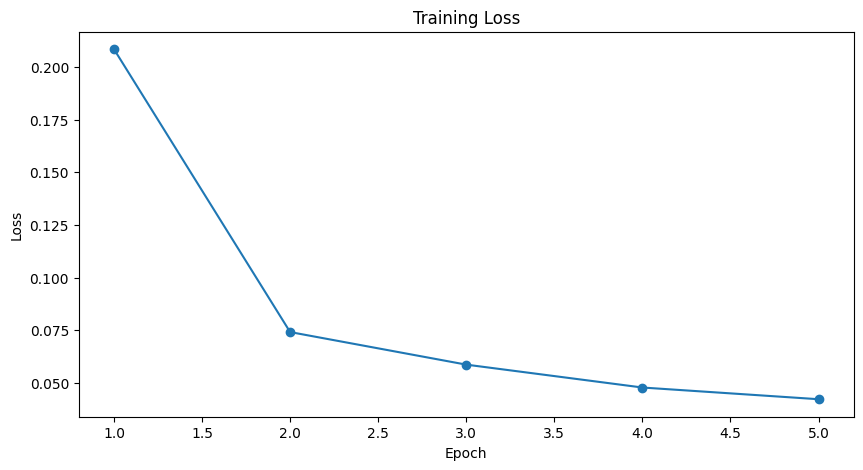

In [48]:
# plot the result
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(losses) + 1), losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

#### next step: faster RCNN model on same dataset

the RCNN model is a type of object detection, but MNIST only has labels for classification. so we need boxes, we need to generate one per image

In [49]:
import torchvision
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# Xtr is normalized, so we go back to raw pixels in 0..1 to find the digit box
Xtr_raw = Xtr * 0.3081 + 0.1307
Xte_raw = Xte * 0.3081 + 0.1307

class MNISTDet(torch.utils.data.Dataset):
    # one box per image: the bounding box of the pixels that are not background
    def __init__(self, X, y):
        self.X, self.y = X, y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        img = self.X[i]
        ys, xs = (img[0] > 0.1).nonzero(as_tuple=True)
        box = torch.stack([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1]).float().unsqueeze(0)
        target = {"boxes": box, "labels": (self.y[i] + 1).view(1)}  # 0 is background, so digit + 1
        return img.repeat(3, 1, 1), target

def collate(batch):
    return tuple(zip(*batch))

det_train_loader = DataLoader(MNISTDet(Xtr_raw[:n_train], ytr[:n_train]), batch_size=16, shuffle=True, collate_fn=collate)
det_test_loader = DataLoader(MNISTDet(Xte_raw[:n_test], yte[:n_test]), batch_size=32, collate_fn=collate)

# check one sample
img, target = MNISTDet(Xtr_raw, ytr)[0]
print(img.shape, target)

torch.Size([3, 28, 28]) {'boxes': tensor([[ 4.,  5., 24., 25.]]), 'labels': tensor([6])}


In [50]:
# faster rcnn with a pretrained backbone, new head for 10 digits + background
rcnn = fasterrcnn_mobilenet_v3_large_fpn(weights="DEFAULT", min_size=128, max_size=128)
in_features = rcnn.roi_heads.box_predictor.cls_score.in_features
rcnn.roi_heads.box_predictor = FastRCNNPredictor(in_features, 11)
rcnn = rcnn.to(device)

rcnn_params = [p for p in rcnn.parameters() if p.requires_grad]
rcnn_optimizer = torch.optim.SGD(rcnn_params, lr=0.01, momentum=0.9, weight_decay=5e-4)

rcnn_epochs = 2
rcnn_losses = []
t0 = time.time()

for epoch in range(rcnn_epochs):
    rcnn.train()
    running = 0.0
    for images, targets in det_train_loader:
        images = [im.to(device) for im in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = rcnn(images, targets)   # in train mode the model returns its losses
        loss = sum(loss_dict.values())

        rcnn_optimizer.zero_grad()
        loss.backward()
        rcnn_optimizer.step()
        running += loss.item() * len(images)

    rcnn_losses.append(running / n_train)
    print(f"Epoch {epoch + 1}/{rcnn_epochs} | Loss: {rcnn_losses[-1]:.4f}")

rcnn_train_time = time.time() - t0
print(f"Training time: {rcnn_train_time:.1f} s")

Epoch 1/2 | Loss: 1.1003
Epoch 2/2 | Loss: 0.6222
Training time: 119.1 s


In [51]:
# evaluating faster rcnn: the label of the best scoring box is the predicted digit
def evaluate_rcnn(model, loader):
    preds, labels = [], []
    model.eval()
    with torch.no_grad():
        for images, targets in loader:
            outputs = model([im.to(device) for im in images])
            for out, t in zip(outputs, targets):
                if len(out["scores"]) > 0:
                    preds.append(out["labels"][out["scores"].argmax()].item() - 1)
                else:
                    preds.append(-1)   # nothing detected counts as wrong
                labels.append(t["labels"].item() - 1)

    # loss: the model only returns losses in train mode, so we compute them without gradients
    total_loss = 0.0
    model.train()
    with torch.no_grad():
        for images, targets in loader:
            images = [im.to(device) for im in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
            total_loss += sum(model(images, targets).values()).item() * len(images)

    return {
        "loss": total_loss / len(labels),
        "accuracy": 100 * accuracy_score(labels, preds),
        "f1": 100 * f1_score(labels, preds, labels=list(range(10)), average="macro"),
    }

results["Faster R-CNN"] = evaluate_rcnn(rcnn, det_test_loader)
results["Faster R-CNN"]["train_time_s"] = rcnn_train_time
results["Faster R-CNN"]["params_M"] = sum(p.numel() for p in rcnn.parameters()) / 1e6
results["Faster R-CNN"]["setup"] = f"{n_train} images, {rcnn_epochs} epochs"
print(results["Faster R-CNN"])

{'loss': 0.5288375301361083, 'accuracy': 98.5, 'f1': 98.51259260650366, 'train_time_s': 119.10864353179932, 'params_M': 18.976354, 'setup': '10000 images, 2 epochs'}


In [52]:
# same cnn architecture, trained from scratch on the same 10k images and 2 epochs
n_train, n_test = 10000, 2000
small_train_loader = DataLoader(TensorDataset(Xtr[:n_train], ytr[:n_train]), batch_size=64, shuffle=True)

torch.manual_seed(0)
cnn_small = nn.Sequential(

    # first convolutional layer
    nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    # second convolutional layer
    nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    # third convolutional layer
    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    # fully connected layers
    nn.Flatten(),
    nn.Linear(in_features=64 * 3 * 3, out_features=128),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(in_features=128, out_features=10)
).to(device)

small_optimizer = torch.optim.Adam(cnn_small.parameters(), lr=0.001, weight_decay=1e-4)
small_epochs = 2

t0 = time.time()

for epoch in range(small_epochs):
    cnn_small.train()
    running_loss = 0.0

    for images, labels in small_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        small_optimizer.zero_grad()
        outputs = cnn_small(images)
        loss = criterion(outputs, labels)
        loss.backward()
        small_optimizer.step()

        running_loss += loss.item() * images.size(0)

    print(f"Epoch {epoch + 1}/{small_epochs} | Loss: {running_loss / n_train:.4f}")

small_time = time.time() - t0

# testing on the same 2000 images as the other models
results["CNN (same data)"] = evaluate_classifier(cnn_small, sub_test_loader)
results["CNN (same data)"]["train_time_s"] = small_time
results["CNN (same data)"]["params_M"] = sum(p.numel() for p in cnn_small.parameters()) / 1e6
results["CNN (same data)"]["setup"] = f"{n_train} images, {small_epochs} epochs"
print(results["CNN (same data)"])

Epoch 1/2 | Loss: 0.6010
Epoch 2/2 | Loss: 0.1471
{'loss': 0.09864108592271804, 'accuracy': 96.8, 'f1': 96.8021225966577, 'train_time_s': 1.161015272140503, 'params_M': 0.098666, 'setup': '10000 images, 2 epochs'}


#### next step: fine tuning VGG16 and AlexNet

we take the models pretrained on ImageNet, freeze the convolutional part and train only a new classifier for the 10 digits. images are resized to 224x224 with 3 channels

In [53]:
import torch.nn.functional as F
from torchvision import models

# train subset for the pretrained models
ft_train_loader = DataLoader(TensorDataset(Xtr[:n_train], ytr[:n_train]), batch_size=64, shuffle=True)

imnet_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
imnet_std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_imagenet(x):
    x = x * 0.3081 + 0.1307                  # back to 0..1
    x = x.repeat(1, 3, 1, 1)                 # 1 channel -> 3 channels
    x = F.interpolate(x, size=224, mode="bilinear", align_corners=False)
    return (x - imnet_mean) / imnet_std

def finetune(name, model, epochs=2, unfreeze_from=None):
    # freeze the convolutional part (optionally unfreeze the last conv block), replace the last layer
    for p in model.features.parameters():
        p.requires_grad = False
    if unfreeze_from is not None:
        for p in model.features[unfreeze_from:].parameters():
            p.requires_grad = True
    model.classifier[6] = nn.Linear(4096, 10)
    model = model.to(device)

    groups = [{"params": model.classifier.parameters(), "lr": 1e-4}]
    if unfreeze_from is not None:
        groups.append({"params": model.features[unfreeze_from:].parameters(), "lr": 1e-5})  # small lr to keep pretrained weights
    opt = torch.optim.Adam(groups)
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        running = 0.0
        for images, labels in ft_train_loader:
            images, labels = to_imagenet(images.to(device)), labels.to(device)
            loss = criterion(model(images), labels)
            opt.zero_grad()
            loss.backward()
            opt.step()
            running += loss.item() * labels.size(0)
        print(f"{name} | Epoch {epoch + 1}/{epochs} | Loss: {running / n_train:.4f}")
    train_time = time.time() - t0

    res = evaluate_classifier(model, sub_test_loader, prep=to_imagenet)
    res["train_time_s"] = train_time
    res["setup"] = f"{n_train} images, {epochs} epochs" + (", last conv block unfrozen" if unfreeze_from is not None else ", features frozen")
    res["params_M"] = sum(p.numel() for p in model.parameters()) / 1e6
    return res

torch.manual_seed(0)
results["AlexNet (frozen)"] = finetune("AlexNet", models.alexnet(weights="DEFAULT"))
print(results["AlexNet (frozen)"])

AlexNet | Epoch 1/2 | Loss: 0.3440
AlexNet | Epoch 2/2 | Loss: 0.0871
{'loss': 0.08180665308237076, 'accuracy': 97.55, 'f1': 97.52761838340577, 'train_time_s': 12.00272512435913, 'setup': '10000 images, 2 epochs, features frozen', 'params_M': 57.04481}


In [54]:
results["VGG16 (frozen)"] = finetune("VGG16", models.vgg16(weights="DEFAULT"))
print(results["VGG16 (frozen)"])

VGG16 | Epoch 1/2 | Loss: 0.3063
VGG16 | Epoch 2/2 | Loss: 0.0462
{'loss': 0.06897772452235222, 'accuracy': 97.5, 'f1': 97.50443261316558, 'train_time_s': 104.34818029403687, 'setup': '10000 images, 2 epochs, features frozen', 'params_M': 134.301514}


#### same setup for everyone

the first CNN saw 60k images for 5 epochs, the others only 10k images for 2 epochs. here we train the CNN again with the same data and epochs, and we also let the last conv block of AlexNet and VGG16 train (with a small learning rate)

In [55]:
results["AlexNet (last block unfrozen)"] = finetune("AlexNet", models.alexnet(weights="DEFAULT"), unfreeze_from=10)
print(results["AlexNet (last block unfrozen)"])

AlexNet | Epoch 1/2 | Loss: 0.3447
AlexNet | Epoch 2/2 | Loss: 0.0803
{'loss': 0.0774960905611515, 'accuracy': 97.6, 'f1': 97.60711420605756, 'train_time_s': 13.377466678619385, 'setup': '10000 images, 2 epochs, last conv block unfrozen', 'params_M': 57.04481}


In [56]:
results["VGG16 (last block unfrozen)"] = finetune("VGG16", models.vgg16(weights="DEFAULT"), unfreeze_from=24)
print(results["VGG16 (last block unfrozen)"])

VGG16 | Epoch 1/2 | Loss: 0.2726
VGG16 | Epoch 2/2 | Loss: 0.0391
{'loss': 0.0768344150185585, 'accuracy': 97.35000000000001, 'f1': 97.36917807985239, 'train_time_s': 120.00002384185791, 'setup': '10000 images, 2 epochs, last conv block unfrozen', 'params_M': 134.301514}


#### comparison of the models

,Setup,Accuracy (%),F1 macro (%),Loss,Training time (s),Params (M)
CNN,"60k images, 5 epochs",98.80,98.787,0.036,17.741,0.099
Faster R-CNN,"10000 images, 2 epochs",98.50,98.513,0.529,119.109,18.976
CNN (same data),"10000 images, 2 epochs",96.80,96.802,0.099,1.161,0.099
AlexNet (frozen),"10000 images, 2 epochs, features frozen",97.55,97.528,0.082,12.003,57.045
VGG16 (frozen),"10000 images, 2 epochs, features frozen",97.50,97.504,0.069,104.348,134.302
AlexNet (last block unfrozen),"10000 images, 2 epochs, last conv block unfrozen",97.60,97.607,0.077,13.377,57.045
VGG16 (last block unfrozen),"10000 images, 2 epochs, last conv block unfrozen",97.35,97.369,0.077,120.000,134.302


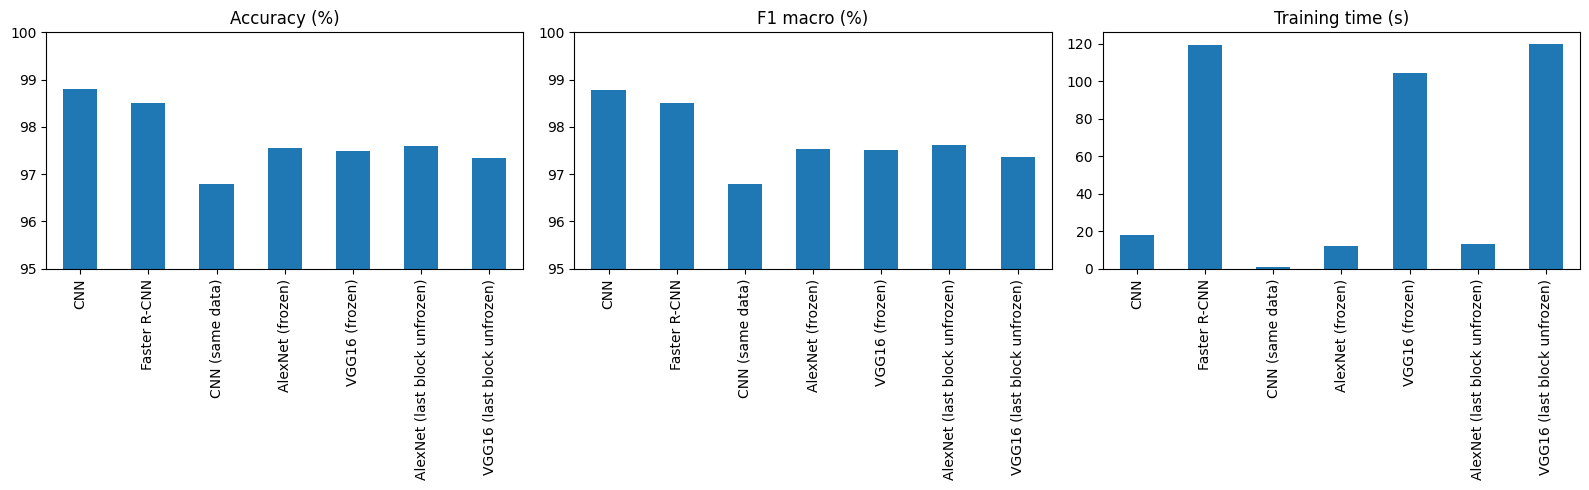

In [57]:
import pandas as pd

table = pd.DataFrame(results).T[["setup", "accuracy", "f1", "loss", "train_time_s", "params_M"]]
table.columns = ["Setup", "Accuracy (%)", "F1 macro (%)", "Loss", "Training time (s)", "Params (M)"]
for col in table.columns[1:]:
    table[col] = table[col].astype(float).round(3)
display(table)

num = table.drop(columns="Setup")
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
num["Accuracy (%)"].plot.bar(ax=axes[0], title="Accuracy (%)", ylim=(95, 100))
num["F1 macro (%)"].plot.bar(ax=axes[1], title="F1 macro (%)", ylim=(95, 100))
num["Training time (s)"].plot.bar(ax=axes[2], title="Training time (s)")
plt.tight_layout()
plt.show()

#### Conclusion:

With the same data (10000 images, 2 epochs), the small CNN trained from scratch gets 96.8%, the pretrained AlexNet and VGG16 get about 97.5%, and **Faster R-CNN** gets 98.5%. So pretrained features and the detector both help when data and training time are limited. Unfreezing the last conv block of AlexNet and VGG16 did not change the result (the differences are 1 to 3 images out of 2000).

But the gain is paid with a large cost. AlexNet and VGG16 have 500 to 1300 times more parameters than our CNN (57M and 134M against 0.1M), and training takes about 10 times longer for AlexNet and about 90 times longer for VGG16. Faster R-CNN has 19M parameters and needed about 100 times more training time than the CNN. It is also an object detector: it predicts boxes too, and here the boxes had to be generated artificially. Its result also changed a lot between two runs (96.35% in the first one and 98.50% in the second), because we did not fix its random seed, so it is less stable than the others.

When the CNN sees all 60000 images (5 epochs), it reaches 98.80% with only 0.1M parameters and 18 seconds of training. This is better than any model trained on 10000 images, and almost the same as Faster R-CNN, which is about 7 times slower to train on 6 times less data.

So for MNIST, a small CNN is the best choice: simple, light, fast and accurate. Fine-tuning pretrained models is useful when data is small and the images look like natural images, which is not the case here (28x28 grayscale digits that had to be resized to 224).

Note: the test subset has only 2000 images, so differences smaller than about 0.3% are not significant.